# 1. Data Collecting (Mengumpulkan Data dari Sumber)


In [ ]:
import os
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [ ]:
# Sumber data
URL_SUMBER = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/taxis.csv"
FILE_DATASET = "dataset_nyc_taxi_2019.csv"

# Ambil data dari sumber jika file lokal belum ada
if not os.path.exists(FILE_DATASET):
    print("Mengunduh data dari sumber...")
    respon = requests.get(URL_SUMBER, timeout=30)
    respon.raise_for_status()              # error jika gagal (status != 200)
    with open(FILE_DATASET, "wb") as f:
        f.write(respon.content)
    print("Data berhasil diunduh dan disimpan sebagai", FILE_DATASET)
else:
    print("File", FILE_DATASET, "sudah ada, tidak perlu mengunduh ulang.")

print("Ukuran file:", round(os.path.getsize(FILE_DATASET) / 1024, 1), "KB")

File dataset_nyc_taxi_2019.csv sudah ada, tidak perlu mengunduh ulang.
Ukuran file: 849.0 KB


In [ ]:
# Validasi syarat minimal jumlah data (>= 1000 baris)
jumlah_baris = sum(1 for _ in open(FILE_DATASET, encoding="utf-8")) - 1  # dikurangi header
print("Jumlah baris data :", jumlah_baris)
print("Memenuhi syarat minimal 1000 baris?", jumlah_baris >= 1000)

Jumlah baris data : 6433
Memenuhi syarat minimal 1000 baris? True


# 2. Data Loading (Memuat Data)


In [ ]:
df = pd.read_csv(FILE_DATASET)
print("Dimensi data (baris, kolom):", df.shape)
df.head()

Dimensi data (baris, kolom): (6433, 14)


,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [ ]:
df.tail()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
6428,2019-03-31 09:51:53,2019-03-31 09:55:27,1,0.75,4.5,1.06,0.0,6.36,green,credit card,East Harlem North,Central Harlem North,Manhattan,Manhattan
6429,2019-03-31 17:38:00,2019-03-31 18:34:23,1,18.74,58.0,0.00,0.0,58.80,green,credit card,Jamaica,East Concourse/Concourse Village,Queens,Bronx
6430,2019-03-23 22:55:18,2019-03-23 23:14:25,1,4.14,16.0,0.00,0.0,17.30,green,cash,Crown Heights North,Bushwick North,Brooklyn,Brooklyn
6431,2019-03-04 10:09:25,2019-03-04 10:14:29,1,1.12,6.0,0.00,0.0,6.80,green,credit card,East New York,East Flatbush/Remsen Village,Brooklyn,Brooklyn
6432,2019-03-13 19:31:22,2019-03-13 19:48:02,1,3.85,15.0,3.36,0.0,20.16,green,credit card,Boerum Hill,Windsor Terrace,Brooklyn,Brooklyn


In [ ]:
# Informasi tipe data dan jumlah nilai non-null tiap kolom
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   pickup           6433 non-null   str    
 1   dropoff          6433 non-null   str    
 2   passengers       6433 non-null   int64  
 3   distance         6433 non-null   float64
 4   fare             6433 non-null   float64
 5   tip              6433 non-null   float64
 6   tolls            6433 non-null   float64
 7   total            6433 non-null   float64
 8   color            6433 non-null   str    
 9   payment          6389 non-null   str    
 10  pickup_zone      6407 non-null   str    
 11  dropoff_zone     6388 non-null   str    
 12  pickup_borough   6407 non-null   str    
 13  dropoff_borough  6388 non-null   str    
dtypes: float64(5), int64(1), str(8)
memory usage: 703.7 KB


In [ ]:
# Statistik deskriptif kolom numerik
df.describe()

,passengers,distance,fare,tip,tolls,total
count,6433.000000,6433.000000,6433.000000,6433.00000,6433.000000,6433.000000
mean,1.539251,3.024617,13.091073,1.97922,0.325273,18.517794
std,1.203768,3.827867,11.551804,2.44856,1.415267,13.815570
min,0.000000,0.000000,1.000000,0.00000,0.000000,1.300000
25%,1.000000,0.980000,6.500000,0.00000,0.000000,10.800000
50%,1.000000,1.640000,9.500000,1.70000,0.000000,14.160000
75%,2.000000,3.210000,15.000000,2.80000,0.000000,20.300000
max,6.000000,36.700000,150.000000,33.20000,24.020000,174.820000


In [ ]:
# Statistik deskriptif kolom kategorikal / teks
df.describe(include="object")

,pickup,dropoff,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
count,6433,6433,6433,6389,6407,6388,6407,6388
unique,6414,6425,2,2,194,203,4,5
top,2019-03-24 00:12:23,2019-03-02 00:58:26,yellow,credit card,Midtown Center,Upper East Side North,Manhattan,Manhattan
freq,2,2,5451,4577,230,245,5268,5206


# 3. Data Cleaning dan Transformation


## 3.1 Cek Missing Value

In [ ]:
missing = df.isnull().sum()
persen = (missing / len(df) * 100).round(2)
pd.DataFrame({"jumlah_missing": missing, "persen (%)": persen})[missing > 0]

,jumlah_missing,persen (%)
payment,44,0.68
pickup_zone,26,0.40
dropoff_zone,45,0.70
pickup_borough,26,0.40
dropoff_borough,45,0.70


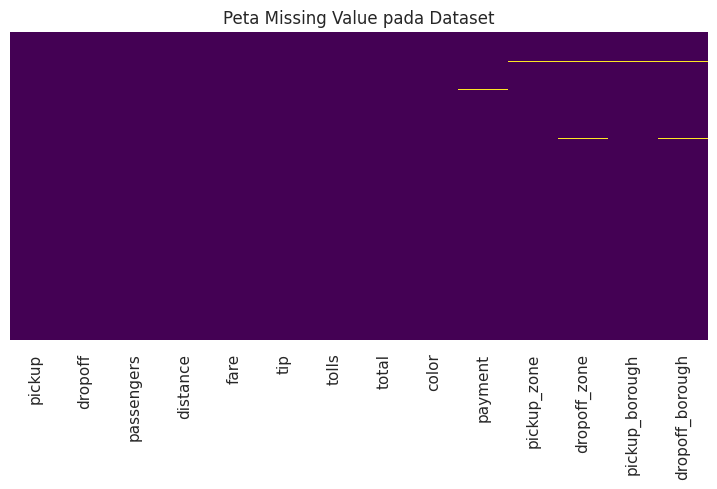

In [ ]:
# Visualisasi missing value
plt.figure(figsize=(9, 4))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Peta Missing Value pada Dataset")
plt.show()

In [ ]:
kolom_kategori_missing = ["payment", "pickup_zone", "dropoff_zone", "pickup_borough", "dropoff_borough"]
for kol in kolom_kategori_missing:
    df[kol] = df[kol].fillna("Unknown")

print("Sisa missing value:", df.isnull().sum().sum())

Sisa missing value: 0


## 3.2 Cek Data Duplikat

In [ ]:
print("Jumlah baris duplikat:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Dimensi setelah drop duplikat:", df.shape)

Jumlah baris duplikat: 0
Dimensi setelah drop duplikat: (6433, 14)


## 3.3 Konversi Tipe Data

In [ ]:
df["pickup"] = pd.to_datetime(df["pickup"])
df["dropoff"] = pd.to_datetime(df["dropoff"])

for kol in ["color", "payment", "pickup_borough", "dropoff_borough"]:
    df[kol] = df[kol].astype("category")

df.dtypes

pickup             datetime64[us]
dropoff            datetime64[us]
passengers                  int64
distance                  float64
fare                      float64
tip                       float64
tolls                     float64
total                     float64
color                    category
payment                  category
pickup_zone                   str
dropoff_zone                  str
pickup_borough           category
dropoff_borough          category
dtype: object

## 3.4 Transformasi / Feature Engineering

In [ ]:
# Durasi perjalanan (menit)
df["duration_min"] = (df["dropoff"] - df["pickup"]).dt.total_seconds() / 60

# Fitur waktu dari waktu penjemputan
df["pickup_hour"] = df["pickup"].dt.hour
df["pickup_dayofweek"] = df["pickup"].dt.dayofweek          # 0 = Senin ... 6 = Minggu
df["is_weekend"] = (df["pickup_dayofweek"] >= 5).astype(int)

# Kecepatan rata-rata (mil/jam) -> dipakai untuk mendeteksi data tidak wajar
df["speed_mph"] = df["distance"] / (df["duration_min"] / 60)

df[["pickup", "dropoff", "duration_min", "pickup_hour", "pickup_dayofweek", "is_weekend", "speed_mph"]].head()

,pickup,dropoff,duration_min,pickup_hour,pickup_dayofweek,is_weekend,speed_mph
0,2019-03-23 20:21:09,2019-03-23 20:27:24,6.250000,20,5,1,15.360000
1,2019-03-04 16:11:55,2019-03-04 16:19:00,7.083333,16,0,0,6.691765
2,2019-03-27 17:53:01,2019-03-27 18:00:25,7.400000,17,2,0,11.108108
3,2019-03-10 01:23:59,2019-03-10 01:49:51,25.866667,1,6,1,17.860825
4,2019-03-30 13:27:42,2019-03-30 13:37:14,9.533333,13,5,1,13.594406


## 3.5 Penanganan Data Tidak Valid dan Outlier

In [ ]:
# Cek data yang tidak masuk akal
print("passengers = 0     :", (df["passengers"] == 0).sum())
print("distance <= 0      :", (df["distance"] <= 0).sum())
print("fare <= 0          :", (df["fare"] <= 0).sum())
print("duration <= 0 menit:", (df["duration_min"] <= 0).sum())
print("duration > 180 mnt :", (df["duration_min"] > 180).sum())
print("speed > 80 mph     :", (df["speed_mph"] > 80).sum())

passengers = 0     : 96
distance <= 0      : 51
fare <= 0          : 0
duration <= 0 menit: 6
duration > 180 mnt : 0
speed > 80 mph     : 11


In [ ]:
# Hapus data yang tidak valid secara logika
sebelum = len(df)
df_clean = df[
    (df["passengers"] > 0) &
    (df["distance"] > 0) &
    (df["fare"] > 0) &
    (df["duration_min"] > 0) &
    (df["duration_min"] <= 180) &
    (df["speed_mph"] <= 80)
].copy()
print(f"Baris sebelum: {sebelum} | sesudah: {len(df_clean)} | dihapus: {sebelum - len(df_clean)}")

Baris sebelum: 6433 | sesudah: 6277 | dihapus: 156


distance      batas = [  -2.38,    6.62]  jumlah outlier = 712
fare          batas = [  -6.25,   27.75]  jumlah outlier = 567
duration_min  batas = [ -11.31,   36.49]  jumlah outlier = 354


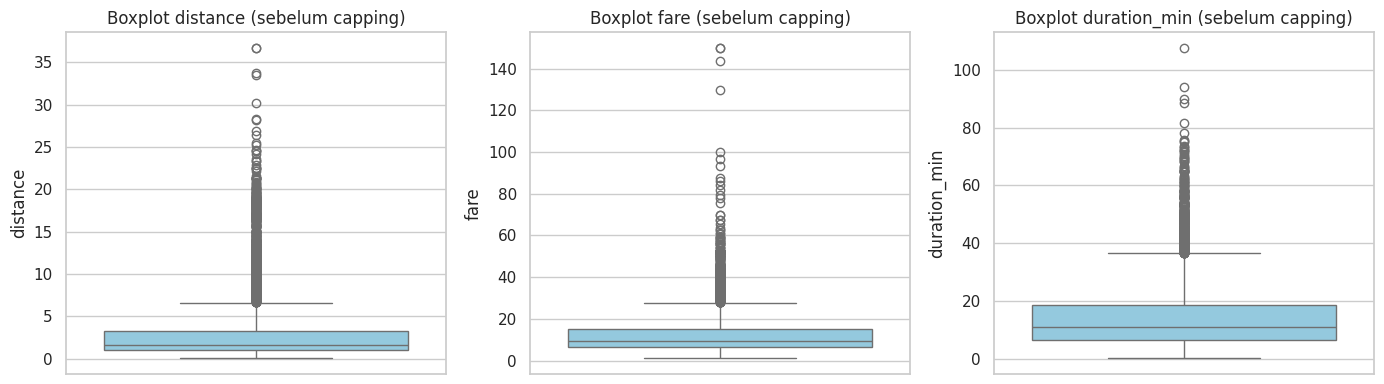

In [ ]:
# Deteksi outlier dengan metode IQR pada kolom numerik utama
kolom_outlier = ["distance", "fare", "duration_min"]

def batas_iqr(seri):
    q1, q3 = seri.quantile(0.25), seri.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

for kol in kolom_outlier:
    bawah, atas = batas_iqr(df_clean[kol])
    n = ((df_clean[kol] < bawah) | (df_clean[kol] > atas)).sum()
    print(f"{kol:13s} batas = [{bawah:7.2f}, {atas:7.2f}]  jumlah outlier = {n}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, kol in zip(axes, kolom_outlier):
    sns.boxplot(y=df_clean[kol], ax=ax, color="skyblue")
    ax.set_title(f"Boxplot {kol} (sebelum capping)")
plt.tight_layout()
plt.show()

In [ ]:
for kol in kolom_outlier:
    bawah, atas = batas_iqr(df_clean[kol])
    df_clean[kol + "_cap"] = df_clean[kol].clip(lower=bawah, upper=atas)

df_clean[["distance", "distance_cap", "fare", "fare_cap", "duration_min", "duration_min_cap"]].describe().round(2)

,distance,distance_cap,fare,fare_cap,duration_min,duration_min_cap
count,6277.00,6277.00,6277.00,6277.00,6277.00,6277.00
mean,3.05,2.43,13.02,11.74,14.45,13.76
std,3.84,1.96,11.25,7.11,11.59,9.39
min,0.01,0.01,1.00,1.00,0.07,0.07
25%,1.00,1.00,6.50,6.50,6.62,6.62
50%,1.66,1.66,9.50,9.50,10.97,10.97
75%,3.25,3.25,15.00,15.00,18.57,18.57
max,36.70,6.62,150.00,27.75,107.67,36.49


## 3.6 Simpan Data Bersih

In [ ]:
df_clean = df_clean.reset_index(drop=True)
df_clean.to_csv("dataset_nyc_taxi_2019_clean.csv", index=False)

print("Dimensi data bersih:", df_clean.shape)
print("Missing value      :", df_clean.isnull().sum().sum())
df_clean.head()

Dimensi data bersih: (6277, 22)
Missing value      : 0


,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough,duration_min,pickup_hour,pickup_dayofweek,is_weekend,speed_mph,distance_cap,fare_cap,duration_min_cap
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan,6.250000,20,5,1,15.360000,1.600,7.0,6.250000
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan,7.083333,16,0,0,6.691765,0.790,5.0,7.083333
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan,7.400000,17,2,0,11.108108,1.370,7.5,7.400000
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan,25.866667,1,6,1,17.860825,6.625,27.0,25.866667
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan,9.533333,13,5,1,13.594406,2.160,9.0,9.533333


# 4. EDA & ExDA

- **EDA (Exploratory Data Analysis):** eksplorasi untuk memahami pola, distribusi, dan hubungan antar variabel.
- **ExDA (Explanatory Data Analysis):** menyajikan temuan secara jelas dan terarah untuk menjawab pertanyaan tertentu.

## 4.1 EDA: Eksplorasi Data

### a. Distribusi Variabel Numerik (Univariate)

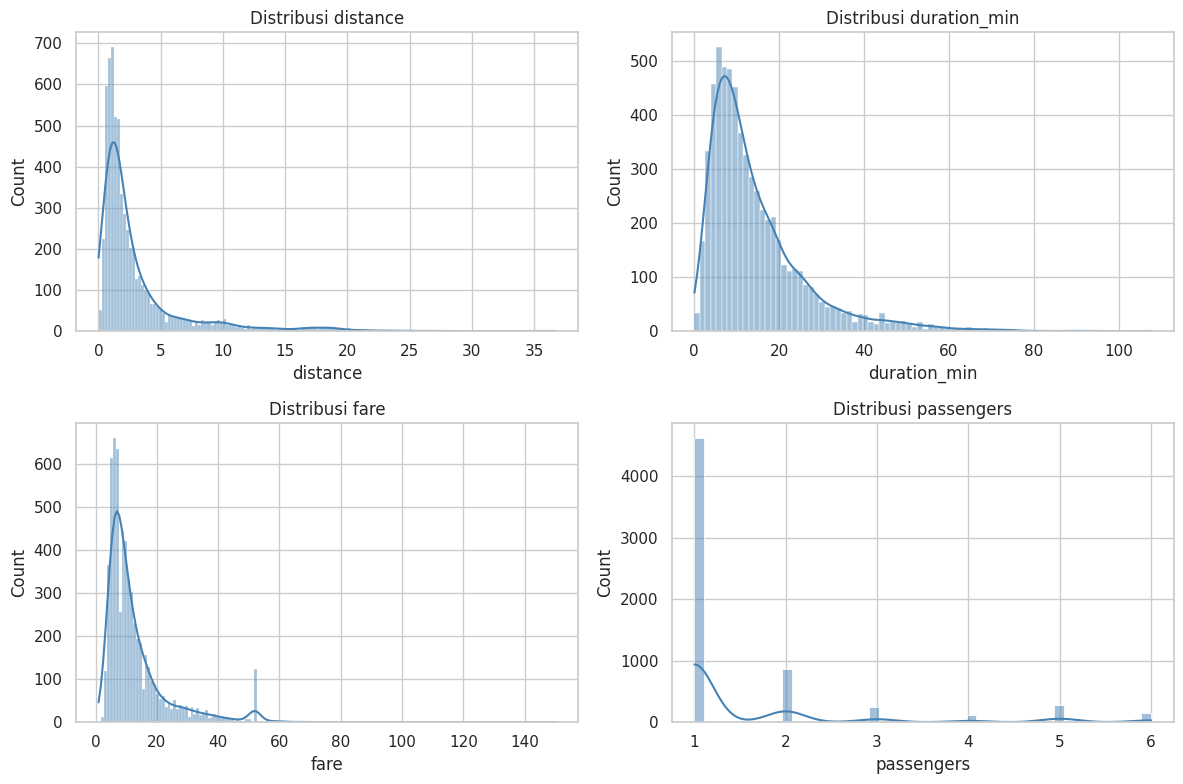

In [ ]:
kolom_num = ["distance", "duration_min", "fare", "passengers"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, kol in zip(axes.ravel(), kolom_num):
    sns.histplot(df_clean[kol], kde=True, ax=ax, color="steelblue")
    ax.set_title(f"Distribusi {kol}")
plt.tight_layout()
plt.show()

### b. Distribusi Variabel Kategorikal

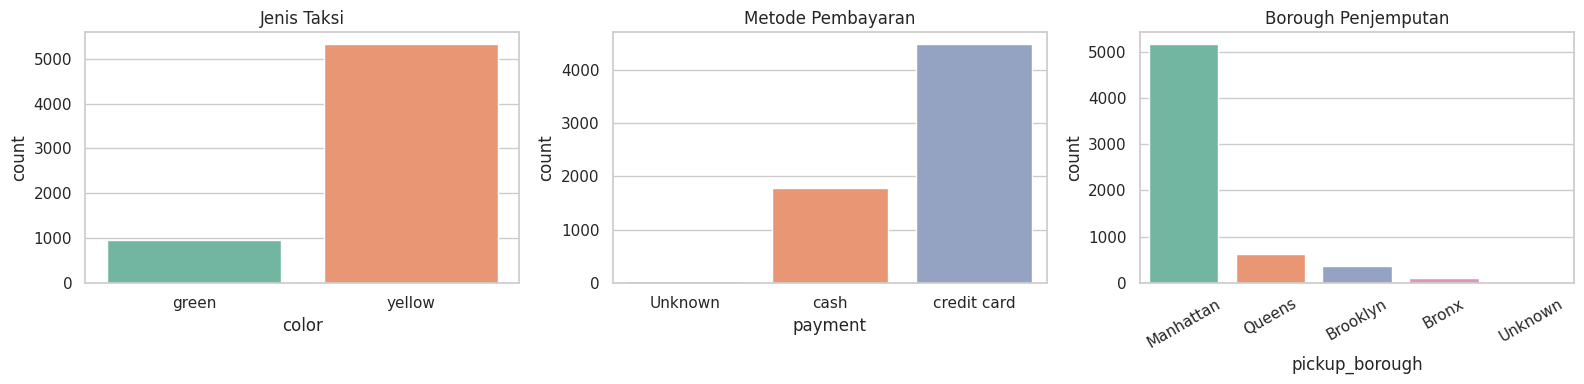

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(data=df_clean, x="color", ax=axes[0], palette="Set2")
axes[0].set_title("Jenis Taksi")
sns.countplot(data=df_clean, x="payment", ax=axes[1], palette="Set2")
axes[1].set_title("Metode Pembayaran")
sns.countplot(data=df_clean, x="pickup_borough", ax=axes[2], palette="Set2",
              order=df_clean["pickup_borough"].value_counts().index)
axes[2].set_title("Borough Penjemputan")
axes[2].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

### c. Korelasi Antar Variabel Numerik (Bivariate)

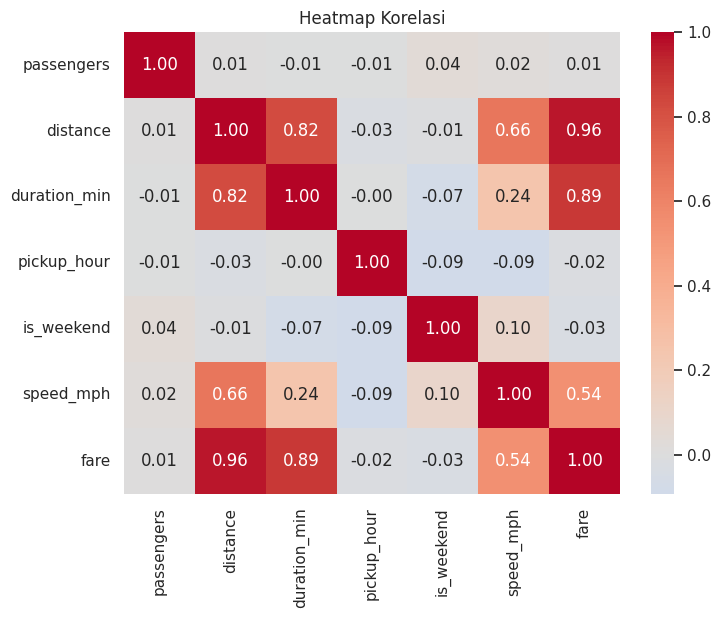

In [ ]:
kolom_korelasi = ["passengers", "distance", "duration_min", "pickup_hour", "is_weekend", "speed_mph", "fare"]
plt.figure(figsize=(8, 6))
sns.heatmap(df_clean[kolom_korelasi].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Heatmap Korelasi")
plt.show()

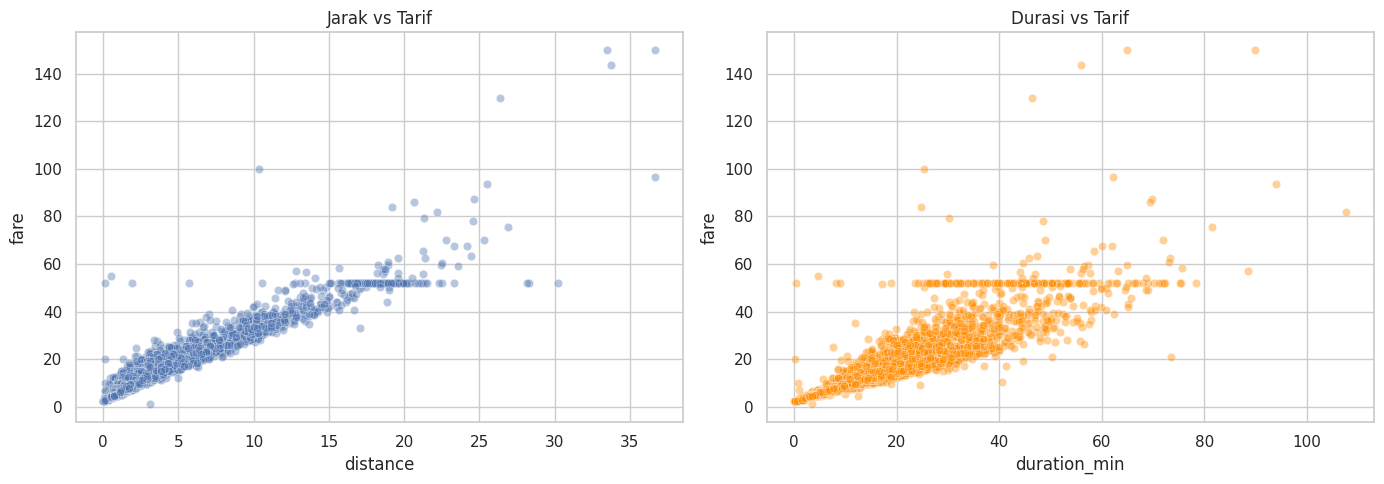

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=df_clean, x="distance", y="fare", alpha=0.4, ax=axes[0])
axes[0].set_title("Jarak vs Tarif")
sns.scatterplot(data=df_clean, x="duration_min", y="fare", alpha=0.4, ax=axes[1], color="darkorange")
axes[1].set_title("Durasi vs Tarif")
plt.tight_layout()
plt.show()

**Temuan EDA:**
- `distance`, `duration_min`, dan `fare` condong ke kanan (right-skewed): sebagian besar perjalanan pendek dan murah.
- `fare` berkorelasi sangat kuat dengan `distance` dan `duration_min`, sehingga keduanya akan menjadi fitur terpenting.
- Jumlah penumpang dan jam penjemputan hampir tidak berkorelasi dengan tarif.

## 4.2 ExDA: Analisis Penjelasan

Tiga pertanyaan yang dijawab dengan visualisasi yang disusun agar mudah dipahami pembaca.

### Pertanyaan 1: Seberapa besar pengaruh jarak terhadap tarif?

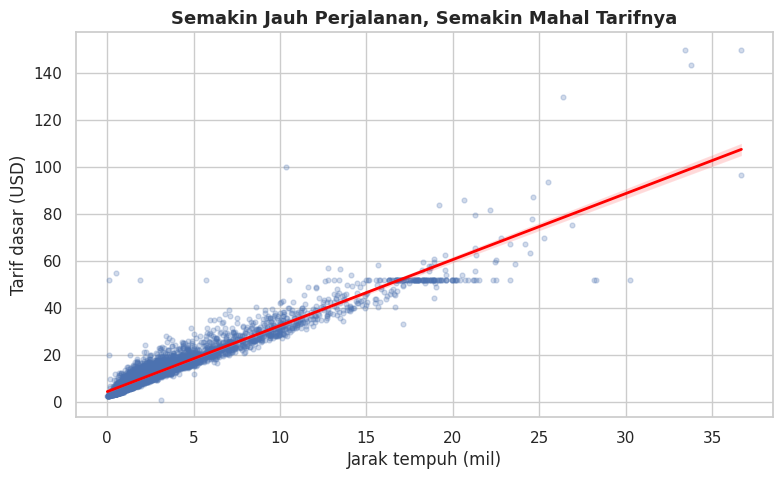

Korelasi jarak-tarif   : 0.959
Rata-rata tarif per mil: USD 4.27


In [ ]:
plt.figure(figsize=(9, 5))
sns.regplot(data=df_clean, x="distance", y="fare", scatter_kws={"alpha": 0.25, "s": 12},
            line_kws={"color": "red", "lw": 2})
plt.title("Semakin Jauh Perjalanan, Semakin Mahal Tarifnya", fontsize=13, fontweight="bold")
plt.xlabel("Jarak tempuh (mil)")
plt.ylabel("Tarif dasar (USD)")
plt.show()

korelasi = df_clean["distance"].corr(df_clean["fare"])
tarif_per_mil = df_clean["fare"].sum() / df_clean["distance"].sum()
print(f"Korelasi jarak-tarif   : {korelasi:.3f}")
print(f"Rata-rata tarif per mil: USD {tarif_per_mil:.2f}")

### Pertanyaan 2: Jam berapa permintaan taksi paling ramai, dan apakah tarifnya berbeda?

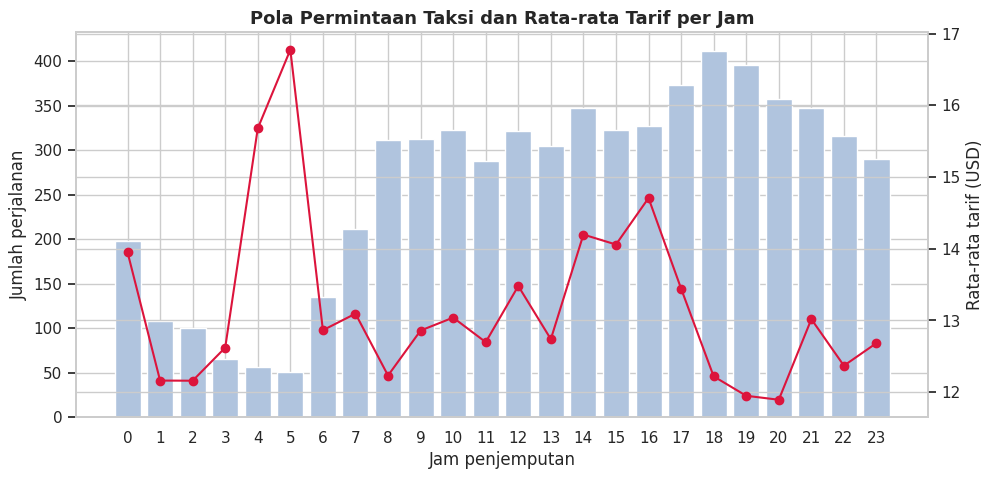

Jam paling ramai: pukul 18:00 (412 perjalanan)


In [ ]:
per_jam = df_clean.groupby("pickup_hour").agg(jumlah_trip=("fare", "count"), rata_tarif=("fare", "mean"))

fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.bar(per_jam.index, per_jam["jumlah_trip"], color="lightsteelblue", label="Jumlah perjalanan")
ax1.set_xlabel("Jam penjemputan")
ax1.set_ylabel("Jumlah perjalanan")
ax2 = ax1.twinx()
ax2.plot(per_jam.index, per_jam["rata_tarif"], color="crimson", marker="o", label="Rata-rata tarif")
ax2.set_ylabel("Rata-rata tarif (USD)")
plt.title("Pola Permintaan Taksi dan Rata-rata Tarif per Jam", fontsize=13, fontweight="bold")
plt.xticks(range(0, 24))
plt.show()

jam_ramai = per_jam["jumlah_trip"].idxmax()
print(f"Jam paling ramai: pukul {jam_ramai}:00 ({per_jam['jumlah_trip'].max()} perjalanan)")

**Jawaban:** Permintaan paling ramai pada sore-malam hari (puncaknya sekitar pukul 18.00) dan paling sepi pada dini hari. Rata-rata tarif tertinggi justru muncul pada pukul 04.00-05.00 dan sore (14.00-16.00), tetapi pada dini hari jumlah perjalanannya sedikit sehingga rata-ratanya kurang stabil.

### Pertanyaan 3: Apakah jenis taksi dan hari (weekday/weekend) memengaruhi tarif?

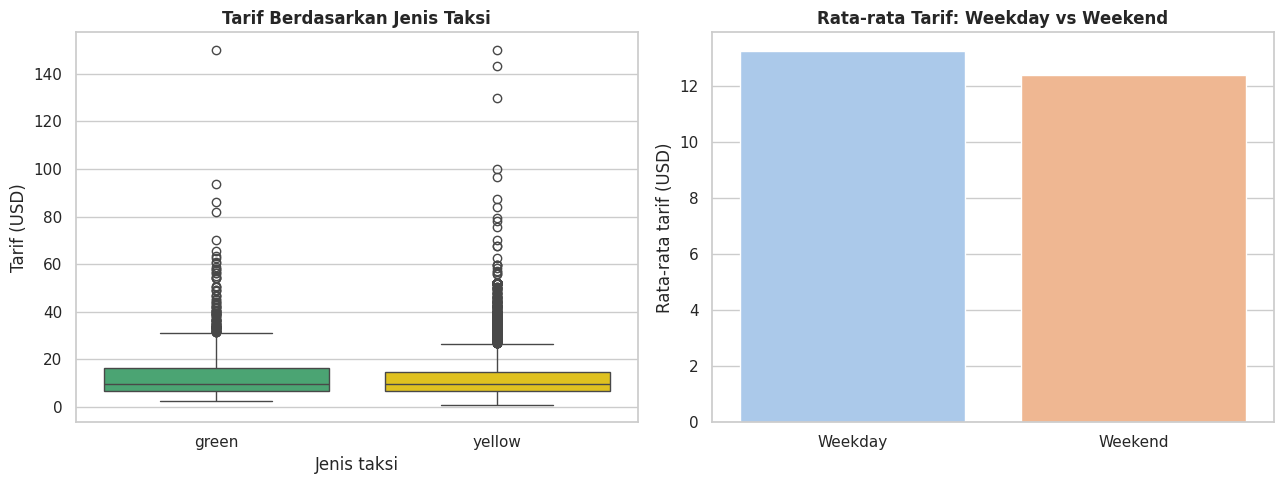

        count   mean  median
color                       
green     956  14.12     9.5
yellow   5321  12.82     9.5

            count   mean  median
is_weekend                      
0            4412  13.27     9.5
1            1865  12.43     9.0

                count   mean
pickup_borough              
Bronx              96  20.54
Brooklyn          374  16.46
Manhattan        5163  11.14
Queens            629  25.21
Unknown            15  14.33


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(data=df_clean, x="color", y="fare", palette={"yellow": "gold", "green": "mediumseagreen"}, ax=axes[0])
axes[0].set_title("Tarif Berdasarkan Jenis Taksi", fontweight="bold")
axes[0].set_xlabel("Jenis taksi")
axes[0].set_ylabel("Tarif (USD)")

sns.barplot(data=df_clean, x="is_weekend", y="fare", ax=axes[1], palette="pastel", errorbar=None)
axes[1].set_xticklabels(["Weekday", "Weekend"])
axes[1].set_title("Rata-rata Tarif: Weekday vs Weekend", fontweight="bold")
axes[1].set_xlabel("")
axes[1].set_ylabel("Rata-rata tarif (USD)")
plt.tight_layout()
plt.show()

print(df_clean.groupby("color")["fare"].agg(["count", "mean", "median"]).round(2))
print()
print(df_clean.groupby("is_weekend")["fare"].agg(["count", "mean", "median"]).round(2))
print()
print(df_clean.groupby("pickup_borough")["fare"].agg(["count", "mean"]).round(2))

**Jawaban:** Taksi hijau punya rata-rata tarif sedikit lebih tinggi daripada taksi kuning (sekitar USD 14,1 vs 12,8), tetapi median keduanya sama sehingga perbedaannya tidak besar. Tarif weekday sedikit lebih tinggi daripada weekend (sekitar USD 13,3 vs 12,4). Perbedaan yang lebih jelas terlihat pada wilayah: perjalanan yang dijemput di Queens dan Bronx rata-rata jauh lebih mahal daripada di Manhattan, karena jaraknya umumnya lebih jauh.

**Kesimpulan tahap 4:** Jarak dan durasi adalah faktor utama penentu tarif; faktor lain (jam, jenis taksi, wilayah) memberi pengaruh tambahan yang lebih kecil. Fitur-fitur ini akan digunakan pada tahap modelling.

# 5. Data Splitting

Data dibagi menjadi **data latih (train, 80%)** dan **data uji (test, 20%)** agar performa model bisa dinilai pada data yang belum pernah dilihat.

**Catatan:** Kolom `tip`, `tolls`, dan `total` **tidak dipakai** sebagai fitur karena `total = fare + tip + tolls`. Memakainya akan menyebabkan *data leakage* (target "bocor" ke fitur).

In [ ]:
from sklearn.model_selection import train_test_split

fitur_numerik = ["passengers", "distance", "duration_min", "pickup_hour", "pickup_dayofweek", "is_weekend"]
fitur_kategori = ["color", "payment", "pickup_borough", "dropoff_borough"]

X = df_clean[fitur_numerik + fitur_kategori]
y = df_clean["fare"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Total data   :", len(X))
print("Data train   :", X_train.shape, f"({len(X_train)/len(X):.0%})")
print("Data test    :", X_test.shape, f"({len(X_test)/len(X):.0%})")

Total data   : 6277
Data train   : (5021, 10) (80%)
Data test    : (1256, 10) (20%)


In [ ]:
# Pastikan distribusi target pada train dan test mirip
pd.DataFrame({"train": y_train.describe(), "test": y_test.describe()}).round(2)

,train,test
count,5021.00,1256.00
mean,13.04,12.92
std,10.95,12.39
min,1.00,2.50
25%,6.50,6.50
50%,9.50,9.00
75%,15.00,14.00
max,130.00,150.00


# 6. Pembangunan Model (Modelling)

Karena target (`fare`) bernilai kontinu, digunakan algoritma **regresi**. Tiga model dibandingkan:
1. **Linear Regression** (baseline)
2. **Decision Tree Regressor**
3. **Random Forest Regressor**

Setiap model dibungkus dalam **Pipeline** yang berisi tahap preprocessing (`StandardScaler` untuk fitur numerik dan `OneHotEncoder` untuk fitur kategorikal) lalu model. Preprocessing hanya di-*fit* pada data train sehingga tidak terjadi kebocoran data dari data test.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), fitur_numerik),
    ("cat", OneHotEncoder(handle_unknown="ignore"), fitur_kategori),
])

model_dict = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=8, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=200, max_depth=12, random_state=42, n_jobs=-1),
}

pipelines, hasil = {}, []
for nama, model in model_dict.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    pipe.fit(X_train, y_train)                 # training
    pred_train = pipe.predict(X_train)
    pred_test = pipe.predict(X_test)           # prediksi data uji
    pipelines[nama] = pipe
    hasil.append({
        "Model": nama,
        "MAE (test)": mean_absolute_error(y_test, pred_test),
        "RMSE (test)": np.sqrt(mean_squared_error(y_test, pred_test)),
        "R2 (train)": r2_score(y_train, pred_train),
        "R2 (test)": r2_score(y_test, pred_test),
    })

hasil_df = pd.DataFrame(hasil).set_index("Model").round(4)
hasil_df

,MAE (test),RMSE (test),R2 (train),R2 (test)
Model,,,,
Linear Regression,0.7902,3.3189,0.9641,0.9281
Decision Tree,0.9782,4.6459,0.9946,0.8592
Random Forest,0.7007,3.8148,0.9956,0.9051


**Interpretasi hasil** (pada saat notebook dijalankan):
- **Linear Regression** memberi R² data uji tertinggi (sekitar 0,93) dan RMSE terendah. Hal ini wajar karena hubungan tarif dengan jarak dan durasi hampir linear (lihat korelasi pada EDA).
- **Random Forest** memiliki MAE terendah, artinya rata-rata selisih prediksinya paling kecil, tetapi RMSE-nya lebih besar karena beberapa perjalanan jarak jauh diprediksi kurang tepat.
- **Decision Tree** menunjukkan gejala *overfitting*: R² data latih sangat tinggi (sekitar 0,99) tetapi R² data uji turun jauh (sekitar 0,86).

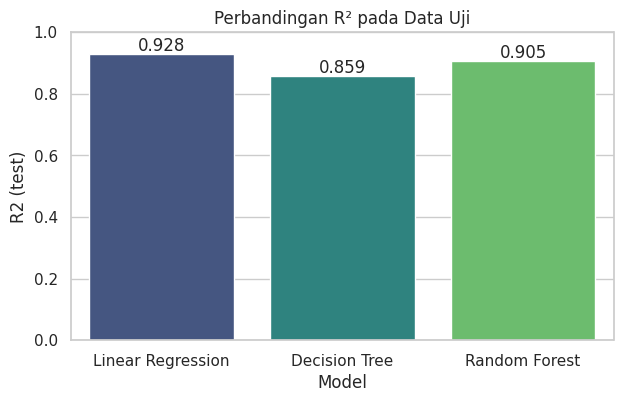

In [ ]:
# Visualisasi perbandingan R2 (test) antar model
plt.figure(figsize=(7, 4))
sns.barplot(x=hasil_df.index, y=hasil_df["R2 (test)"], palette="viridis")
plt.title("Perbandingan R² pada Data Uji")
plt.ylim(0, 1)
for i, v in enumerate(hasil_df["R2 (test)"]):
    plt.text(i, v + 0.01, f"{v:.3f}", ha="center")
plt.show()

Model terbaik: Linear Regression


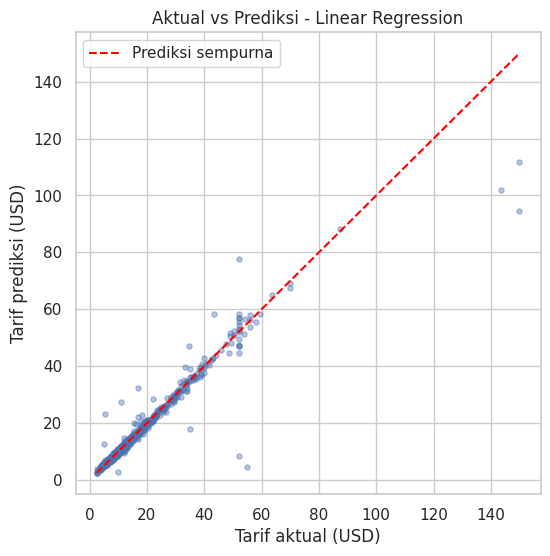

In [ ]:
# Model terbaik berdasarkan R2 pada data uji
nama_terbaik = hasil_df["R2 (test)"].idxmax()
model_terbaik = pipelines[nama_terbaik]
pred_terbaik = model_terbaik.predict(X_test)
print("Model terbaik:", nama_terbaik)

plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred_terbaik, alpha=0.4, s=14)
batas = [y_test.min(), y_test.max()]
plt.plot(batas, batas, color="red", linestyle="--", label="Prediksi sempurna")
plt.xlabel("Tarif aktual (USD)")
plt.ylabel("Tarif prediksi (USD)")
plt.title(f"Aktual vs Prediksi - {nama_terbaik}")
plt.legend()
plt.show()

In [ ]:
# Contoh 10 hasil prediksi
contoh = X_test.copy()
contoh["fare_aktual"] = y_test
contoh["fare_prediksi"] = pred_terbaik.round(2)
contoh["selisih"] = (contoh["fare_aktual"] - contoh["fare_prediksi"]).round(2)
contoh[["distance", "duration_min", "fare_aktual", "fare_prediksi", "selisih"]].head(10)

,distance,duration_min,fare_aktual,fare_prediksi,selisih
2792,0.70,5.566667,5.5,5.63,-0.13
3006,2.30,20.550000,14.0,13.47,0.53
1536,5.70,20.633333,19.5,20.15,-0.65
2812,0.55,3.566667,4.5,4.63,-0.13
2906,0.50,3.683333,4.5,4.66,-0.16
2195,1.40,4.616667,6.0,6.61,-0.61
2115,3.56,23.666667,16.5,16.91,-0.41
4366,0.98,10.800000,8.0,7.69,0.31
4812,1.86,7.683333,8.5,8.48,0.02
561,3.48,23.633333,16.5,16.65,-0.15


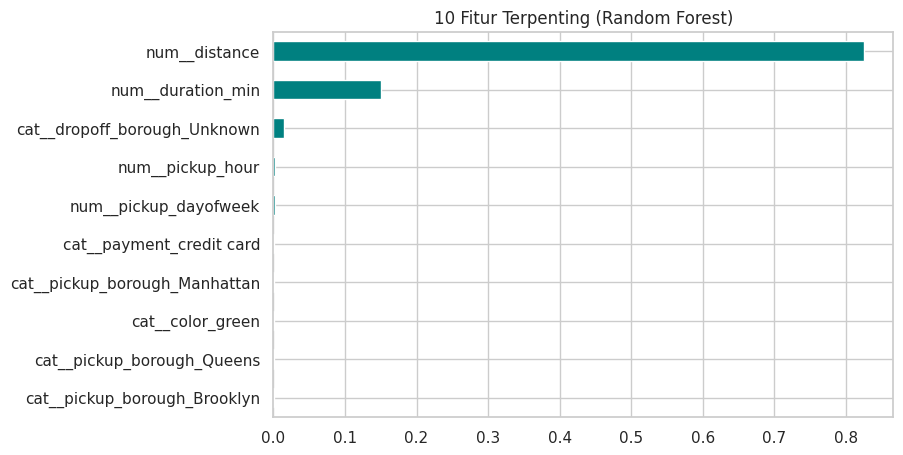

In [ ]:
# Fitur terpenting menurut Random Forest
rf = pipelines["Random Forest"]
nama_fitur = rf.named_steps["prep"].get_feature_names_out()
pentingnya = pd.Series(rf.named_steps["model"].feature_importances_, index=nama_fitur)
pentingnya.nlargest(10).sort_values().plot(kind="barh", figsize=(8, 5), color="teal")
plt.title("10 Fitur Terpenting (Random Forest)")
plt.show()